<a href="https://colab.research.google.com/github/Joyasree462/Computer-Graphics-and-Image-Processing/blob/main/4_Implementation_of_Different_Spatial_Filters_(Masks)_on_a_Single_Image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [49]:
#  Upload One Image
from google.colab import files
uploaded = files.upload()


Saving image - 6.jpg to image - 6.jpg


In [50]:
# Step 3: Read Image
filename = next(iter(uploaded.keys()))
img = cv2.imread(filename)

if img is None:
    raise ValueError("Image could not be loaded.")

# Convert to Grayscale for Sobel
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [51]:
# Sobel Operator
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.convertScaleAbs(
    cv2.magnitude(sobel_x, sobel_y)
)

In [52]:
# Box Filter
box = cv2.boxFilter(img, -1, (5, 5))

In [53]:
# Weighted Average Filter
kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

weighted = cv2.filter2D(img, -1, kernel)

In [54]:
#  Gaussian Filter
gaussian = cv2.GaussianBlur(img, (5, 5), 0)

#  Sharpening Filter
sharp_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpen = cv2.filter2D(img, -1, sharp_kernel)

In [55]:
#  Min Filter
min_filter = cv2.erode(
    img, np.ones((3, 3), np.uint8)
)

In [56]:
#  Max Filter
max_filter = cv2.dilate(
    img, np.ones((3, 3), np.uint8)
)

In [57]:
#  Mean Filter
mean_filter = cv2.blur(img, (3, 3))

#  Median Filter
median_filter = cv2.medianBlur(img, 3)

In [58]:
#  Store All Results
results = [
    ("Sobel Operator", sobel, False),
    ("Box Filter", box, True),
    ("Weighted Average Filter", weighted, True),
    ("Gaussian Filter", gaussian, True),
    ("Sharpening Filter", sharpen, True),
    ("Min Filter", min_filter, True),
    ("Max Filter", max_filter, True),
    ("Mean Filter", mean_filter, True),
    ("Median Filter", median_filter, True)
]

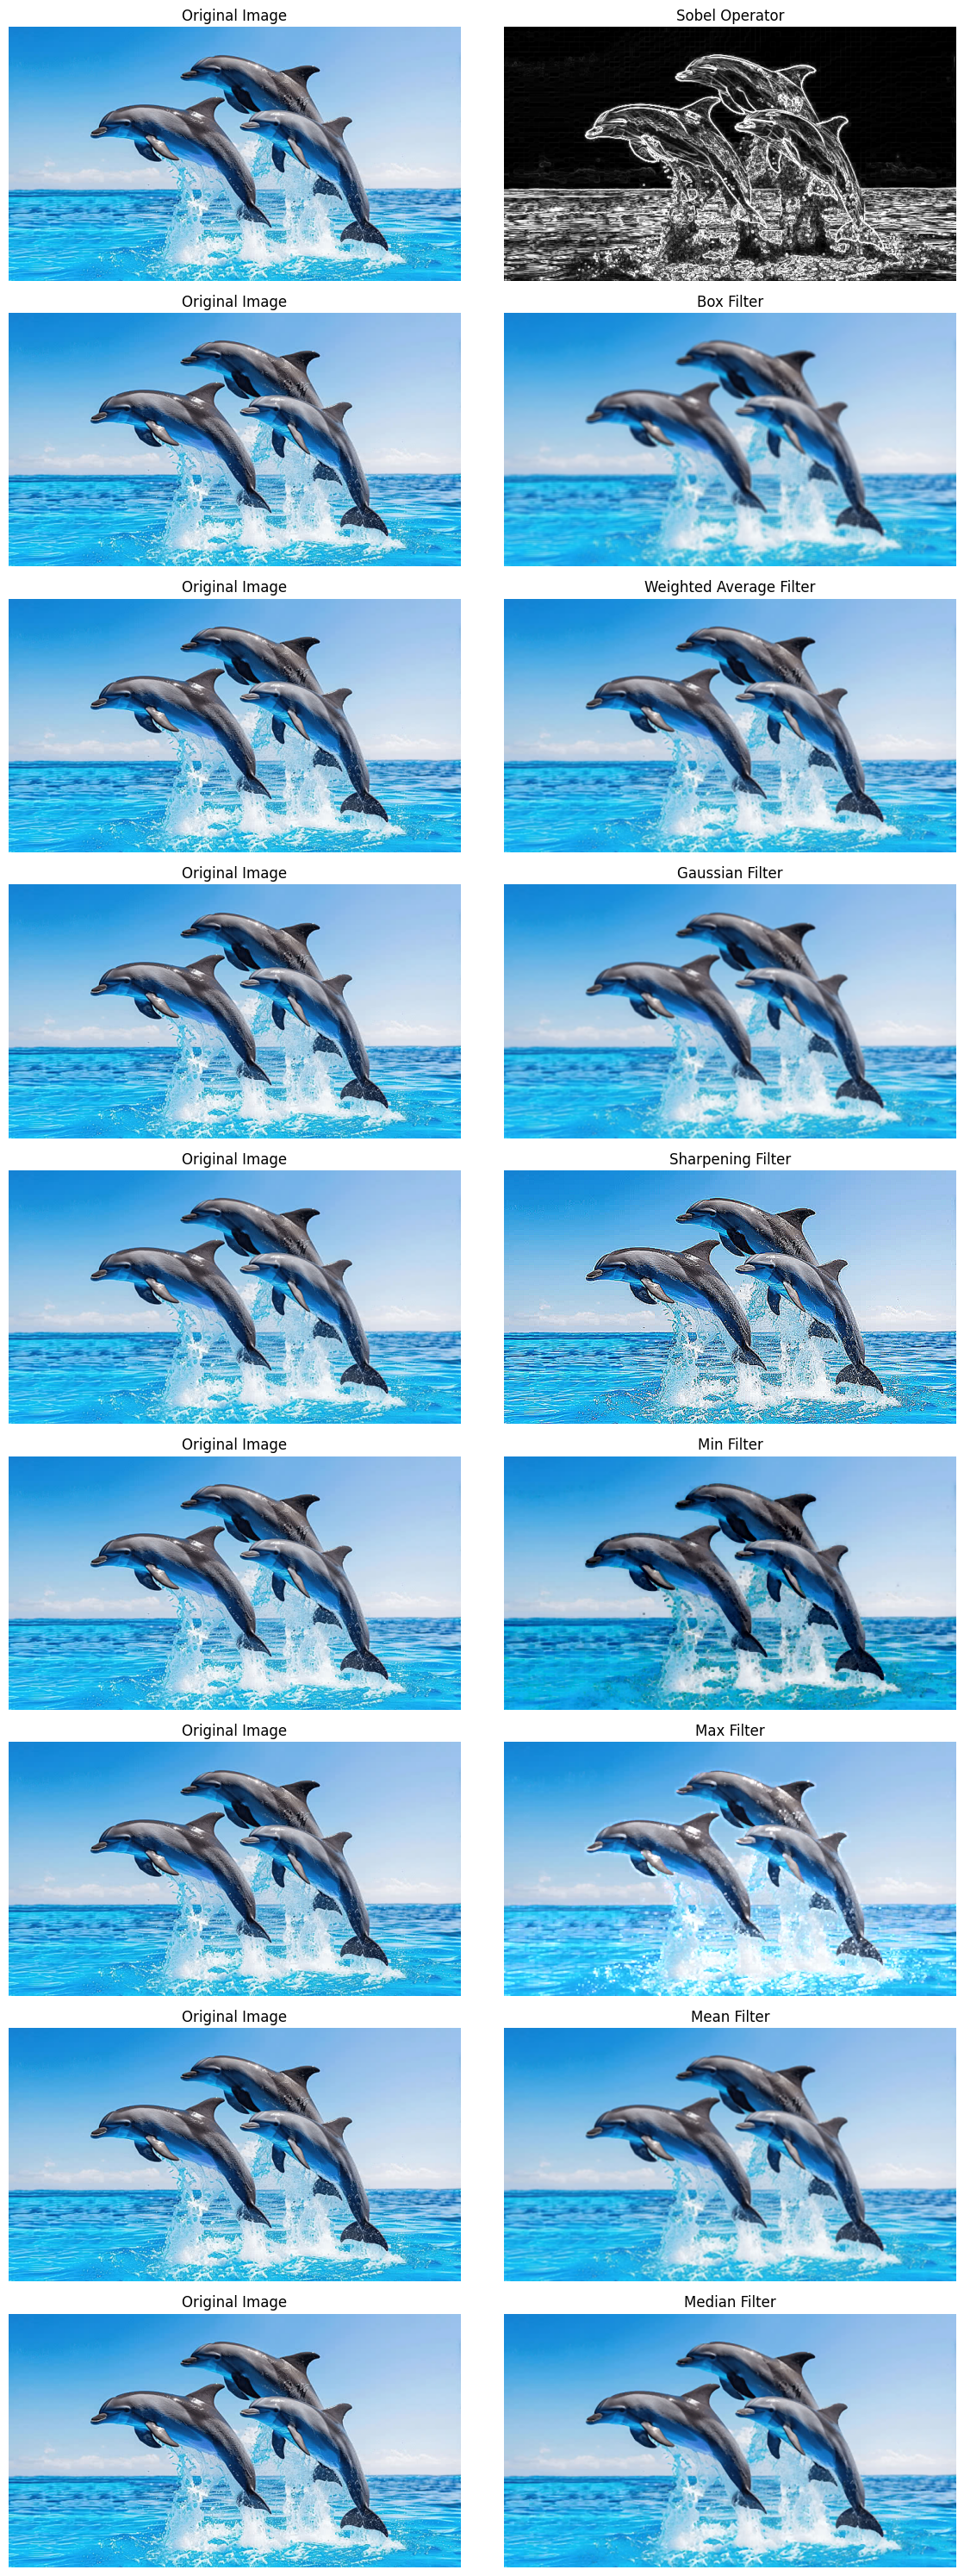

In [59]:
#  Display Original Beside Each Output
fig, axes = plt.subplots(9, 2, figsize=(12, 30))

for i, (title, output, is_color) in enumerate(results):

    # Original Image
    axes[i, 0].imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title("Original Image")
    axes[i, 0].axis('off')

    # Filtered Output
    if is_color:
        output = cv2.cvtColor(
            output, cv2.COLOR_BGR2RGB
        )
        axes[i, 1].imshow(output)
    else:
        axes[i, 1].imshow(output, cmap='gray')

    axes[i, 1].set_title(title)
    axes[i, 1].axis('off')

plt.tight_layout()